## Ayda Pirandakh
## Clustering Project - Customer Segmentation

##  Imports

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

## Read Data

In [103]:
df = pd.read_csv("Customer.csv")
print("Initial Shape:", df.shape)
df.head()

Initial Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data Overview

In [104]:
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

## Encode Gender

## Initial EDA (Before Cleaning)

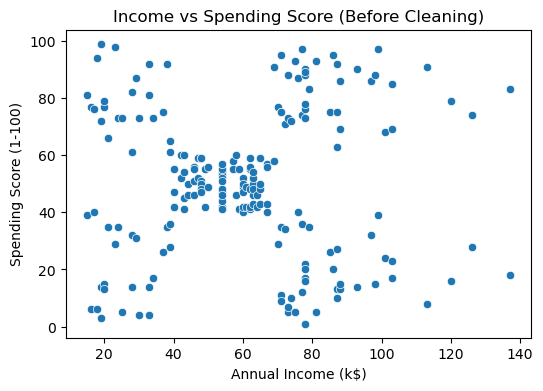

In [105]:
plt.figure(figsize=(6,4))
sns.scatterplot(
    x=df["Annual Income (k$)"],
    y=df["Spending Score (1-100)"]
)
plt.title("Income vs Spending Score (Before Cleaning)")
plt.show()


## Outlier Removal (IQR Method)

In [106]:
numeric_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (198, 5)


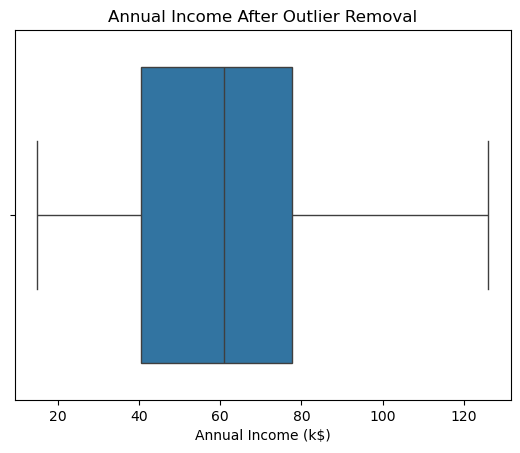

In [107]:
sns.boxplot(x=df["Annual Income (k$)"])
plt.title("Annual Income After Outlier Removal")
plt.show()


## EDA (After Cleaning)

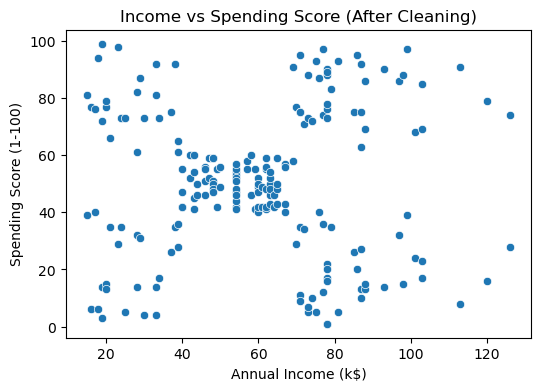

In [108]:
plt.figure(figsize=(6,4))
sns.scatterplot(
    x=df["Annual Income (k$)"],
    y=df["Spending Score (1-100)"]
)
plt.title("Income vs Spending Score (After Cleaning)")
plt.show()


## Feature Selection

In [109]:
X = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]


## Normalization

In [110]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## K-means

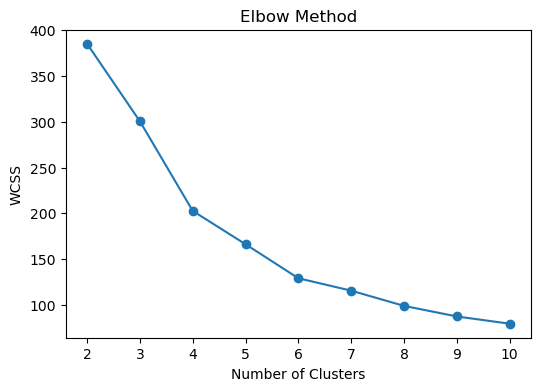

In [111]:
# Elbow Method
import warnings
warnings.filterwarnings("ignore")
wcss = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(range(2,11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()


In [112]:
# K-Means Model
import warnings
warnings.filterwarnings("ignore")
kmeans = KMeans(n_clusters=4, random_state=42)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# Silhouette Score
kmeans_silhouette = silhouette_score(X_scaled, df["KMeans_Cluster"])
print("K-Means Silhouette Score:", round(kmeans_silhouette, 3))


K-Means Silhouette Score: 0.406


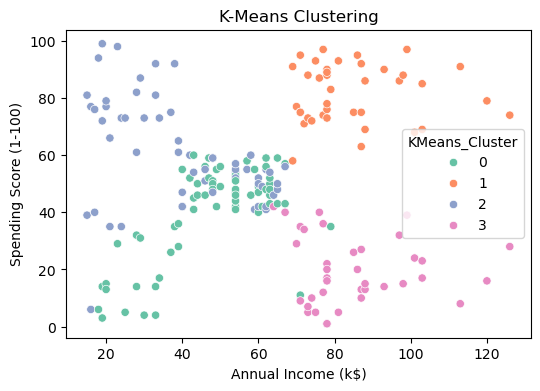

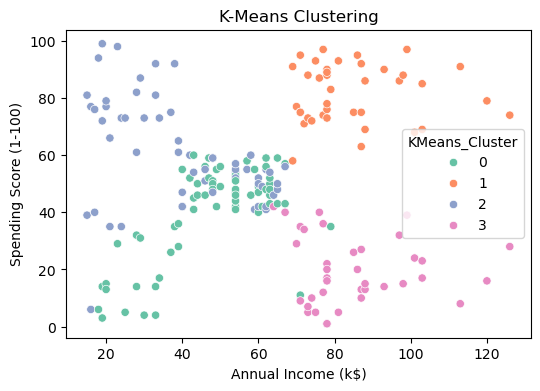

In [113]:
# K-Means Visualization
plt.figure(figsize=(6,4))
sns.scatterplot(
    x=df["Annual Income (k$)"],
    y=df["Spending Score (1-100)"],
    hue=df["KMeans_Cluster"],
    palette="Set2"
)
plt.title("K-Means Clustering")
plt.show()
# =========================
# 11. K-Means Visualization
# =========================
plt.figure(figsize=(6,4))
sns.scatterplot(
    x=df["Annual Income (k$)"],
    y=df["Spending Score (1-100)"],
    hue=df["KMeans_Cluster"],
    palette="Set2"
)
plt.title("K-Means Clustering")
plt.show()


## DBSCAN

In [114]:
# DBSCAN Model
dbscan = DBSCAN(eps=0.6, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"].value_counts()


DBSCAN_Cluster
 0    135
 1     35
-1     28
Name: count, dtype: int64

In [115]:
# DBSCAN Evaluation
# Remove noise for silhouette
dbscan_labels = df["DBSCAN_Cluster"]
mask = dbscan_labels != -1

if len(set(dbscan_labels[mask])) > 1:
    dbscan_silhouette = silhouette_score(
        X_scaled[mask],
        dbscan_labels[mask]
    )
    print("DBSCAN Silhouette Score:", round(dbscan_silhouette, 3))
else:
    print("DBSCAN Silhouette Score: Not defined (single cluster)")


DBSCAN Silhouette Score: 0.279


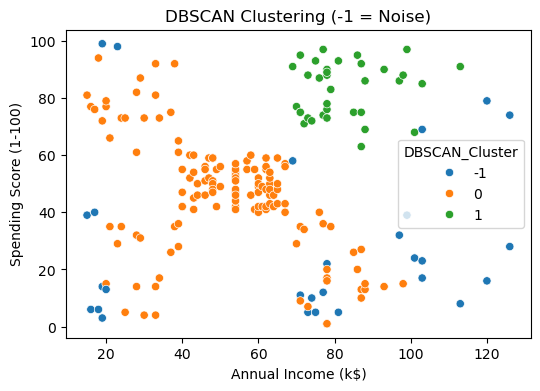

In [116]:
# DBSCAN Visualization
plt.figure(figsize=(6,4))
sns.scatterplot(
    x=df["Annual Income (k$)"],
    y=df["Spending Score (1-100)"],
    hue=df["DBSCAN_Cluster"],
    palette="tab10"
)
plt.title("DBSCAN Clustering (-1 = Noise)")
plt.show()


## Hierarchical Clustering

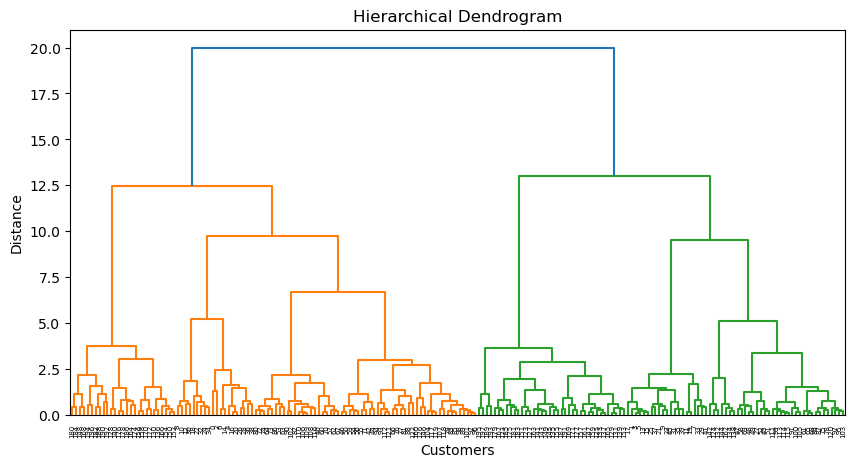

In [117]:
# Dendrogram
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(10,5))
dendrogram(linked)
plt.title("Hierarchical Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()


In [118]:
#  Hierarchical Model
hc = AgglomerativeClustering(n_clusters=4)
df["Hierarchical_Cluster"] = hc.fit_predict(X_scaled)

hc_silhouette = silhouette_score(X_scaled, df["Hierarchical_Cluster"])
print("Hierarchical Silhouette Score:", round(hc_silhouette, 3))


Hierarchical Silhouette Score: 0.369
